# Example 2 — TDC calibration from a code density test

The ring-oscillator TDC does not have equal code widths, so a flat
`code × 71.6 ps` conversion is only an average. The code density test measures
the real widths. You illuminate the sensor with light that is uncorrelated with
the oscillator, and each code's hit probability is then proportional to its
width.

The ring has only 8 distinct tap widths, which repeat every lap. The whole
calibration is therefore a `(32, 32, 8)` table per SPAD, and the same table
serves every reference clock.

Full explanation: [TDC calibration](../docs/guide/tdc_calibration.md).

## What you need

- a density-test acquisition: uniform, uncorrelated light (a lamp, or dark
  counts), recorded per micropixel with the timestamping programs `S0T`,
  `S1T`, `S2T` and `S3T`. Only the program tag matters: files are matched as
  `*_<tag>*.bin`, so `density_test_S2T12.bin` and `lamp_S2T3.bin` both count.
- `nframes`, the frames per file you acquired with.
- `clock_period_s`, one period of the reference clock the test ran at:
  `500e-9` at 2 MHz, `100e-9` at 10 MHz. This is the one time dapkel cannot
  derive from the data, because it sets the absolute scale. A slow clock sweeps
  more laps and so measures the ring period best; 2 MHz is the usual choice.

Run [data quality](01_data_quality.ipynb) on one tag first. A density test on a TDC
that never stopped produces a calibration table that looks fine and is wrong.

## 1. Point dapkel at the data

In [1]:
import glob
import os

from IPython.display import Image, display


def show_figures(folder, kind):
    """Show the figures plot_* saved to results/<kind>/ (it closes them)."""
    for png in sorted(glob.glob(os.path.join(folder, "results", kind, "*.png"))):
        display(Image(filename=png))

In [2]:
from dapkel.functions import tdc_calibration as tc

path = r"D:\Kelpie\2026.10.30"
nframes = 2**15
clock_period_s = 100e-9  # 10 MHz

## 2. Build the tables

One table per SPAD tag found, saved as `processed/TDC_COMPACT_<tag>.npy`. The
printout gives each SPAD's mean ring period and its spread across pixels.
Expect about 600 ps (an LSB of ~75 ps) with ~1.2 % rms spread.

In [3]:
saved = tc.process_tdc_calibration(path, nframes, clock_period_s)
# a quick look first: tc.process_tdc_calibration(path, nframes, clock_period_s, max_files=10)
print(saved)


> > > Tap widths for 'S0T' (10 files, 10 MHz clock) < < <


S0T: 100%|██████████| 10/10 [00:42<00:00,  4.27s/it]


  ring period 597.13 ps (+/- 1.17 % across pixels)  dead pixels 0

> > > Saved to D:\Kelpie\2026.10.30\processed\TDC_COMPACT_S0T.npy < < <

> > > Tap widths for 'S1T' (10 files, 10 MHz clock) < < <


S1T: 100%|██████████| 10/10 [00:29<00:00,  2.94s/it]


  ring period 597.15 ps (+/- 1.18 % across pixels)  dead pixels 0

> > > Saved to D:\Kelpie\2026.10.30\processed\TDC_COMPACT_S1T.npy < < <

> > > Tap widths for 'S2T' (10 files, 10 MHz clock) < < <


S2T: 100%|██████████| 10/10 [00:26<00:00,  2.62s/it]


  ring period 597.21 ps (+/- 1.17 % across pixels)  dead pixels 0

> > > Saved to D:\Kelpie\2026.10.30\processed\TDC_COMPACT_S2T.npy < < <

> > > Tap widths for 'S3T' (10 files, 10 MHz clock) < < <


S3T: 100%|██████████| 10/10 [00:23<00:00,  2.35s/it]

  ring period 597.25 ps (+/- 1.18 % across pixels)  dead pixels 0

> > > Saved to D:\Kelpie\2026.10.30\processed\TDC_COMPACT_S3T.npy < < <
['D:\\Kelpie\\2026.10.30\\processed\\TDC_COMPACT_S0T.npy', 'D:\\Kelpie\\2026.10.30\\processed\\TDC_COMPACT_S1T.npy', 'D:\\Kelpie\\2026.10.30\\processed\\TDC_COMPACT_S2T.npy', 'D:\\Kelpie\\2026.10.30\\processed\\TDC_COMPACT_S3T.npy']


To build only some SPADs, pass `tags`:

In [4]:
# tc.process_tdc_calibration(path, nframes, clock_period_s, tags=("S0T",))

## 3. Quality check

`plot_tdc_calibration` saves one figure per SPAD to `results/tdc_calibration/`:

- **top panel:** the chosen pixel's tap DNL against the array median and its
  5–95 % band;
- **bottom panel:** the ring period across all pixels.

It returns the tables in picoseconds.


> > > Plot is saved as TDC_COMPACT_S0T_qa.png in D:\Kelpie\2026.10.30\results\tdc_calibration < < <

> > > Plot is saved as TDC_COMPACT_S1T_qa.png in D:\Kelpie\2026.10.30\results\tdc_calibration < < <

> > > Plot is saved as TDC_COMPACT_S2T_qa.png in D:\Kelpie\2026.10.30\results\tdc_calibration < < <

> > > Plot is saved as TDC_COMPACT_S3T_qa.png in D:\Kelpie\2026.10.30\results\tdc_calibration < < <


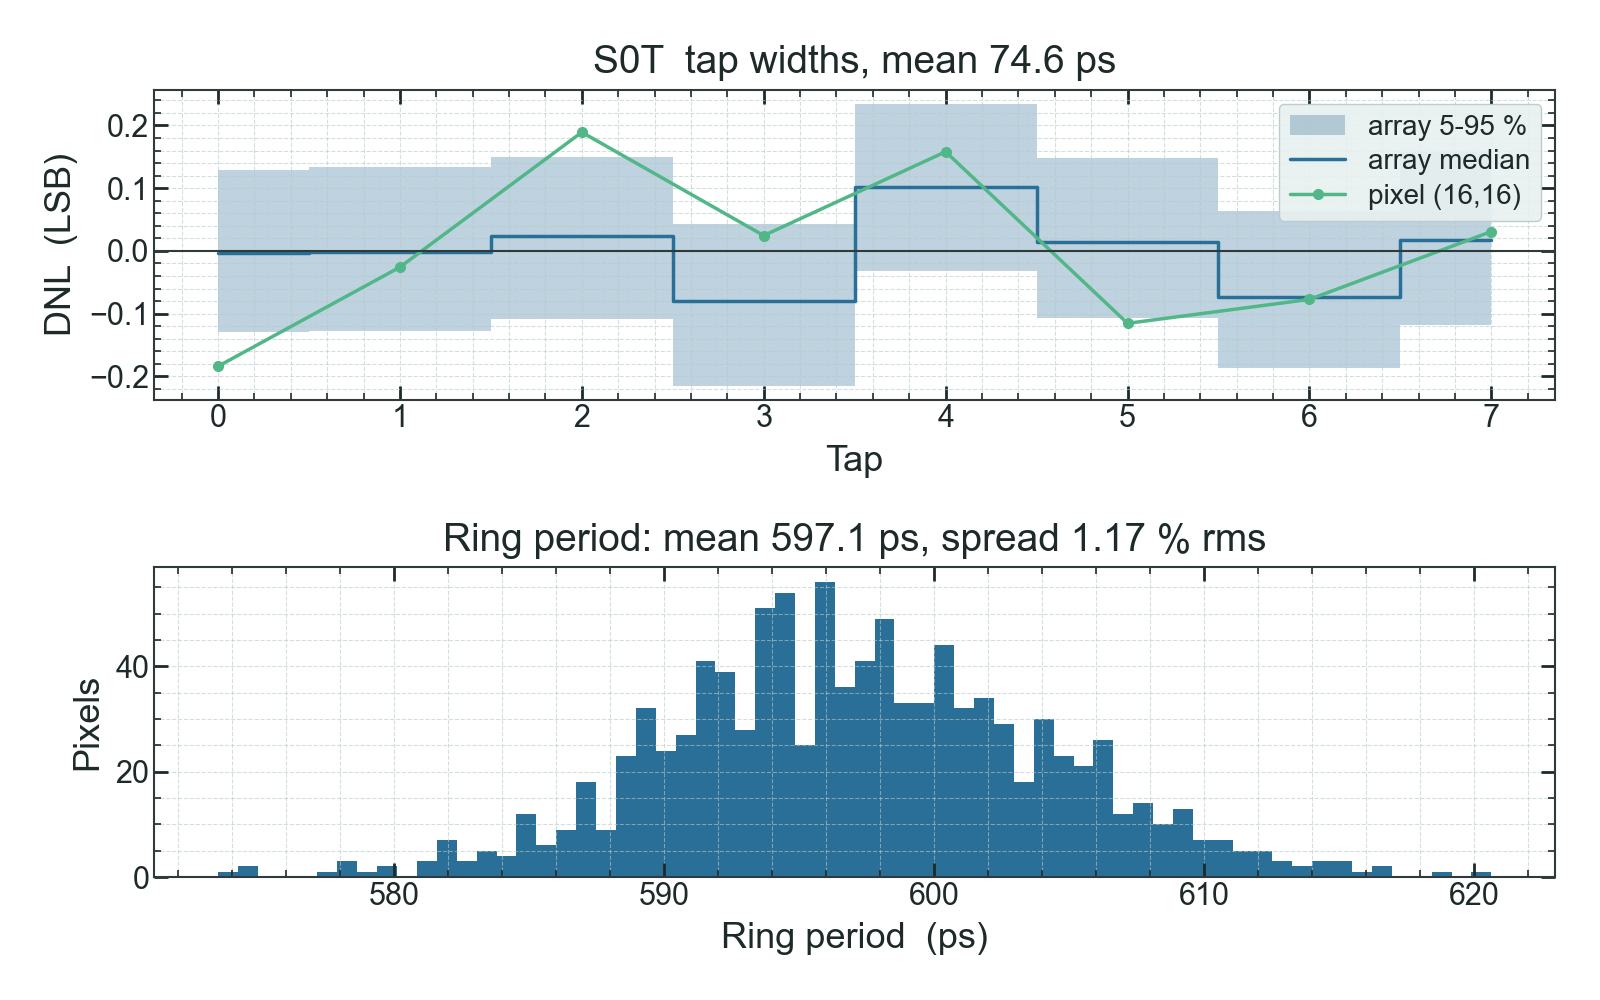

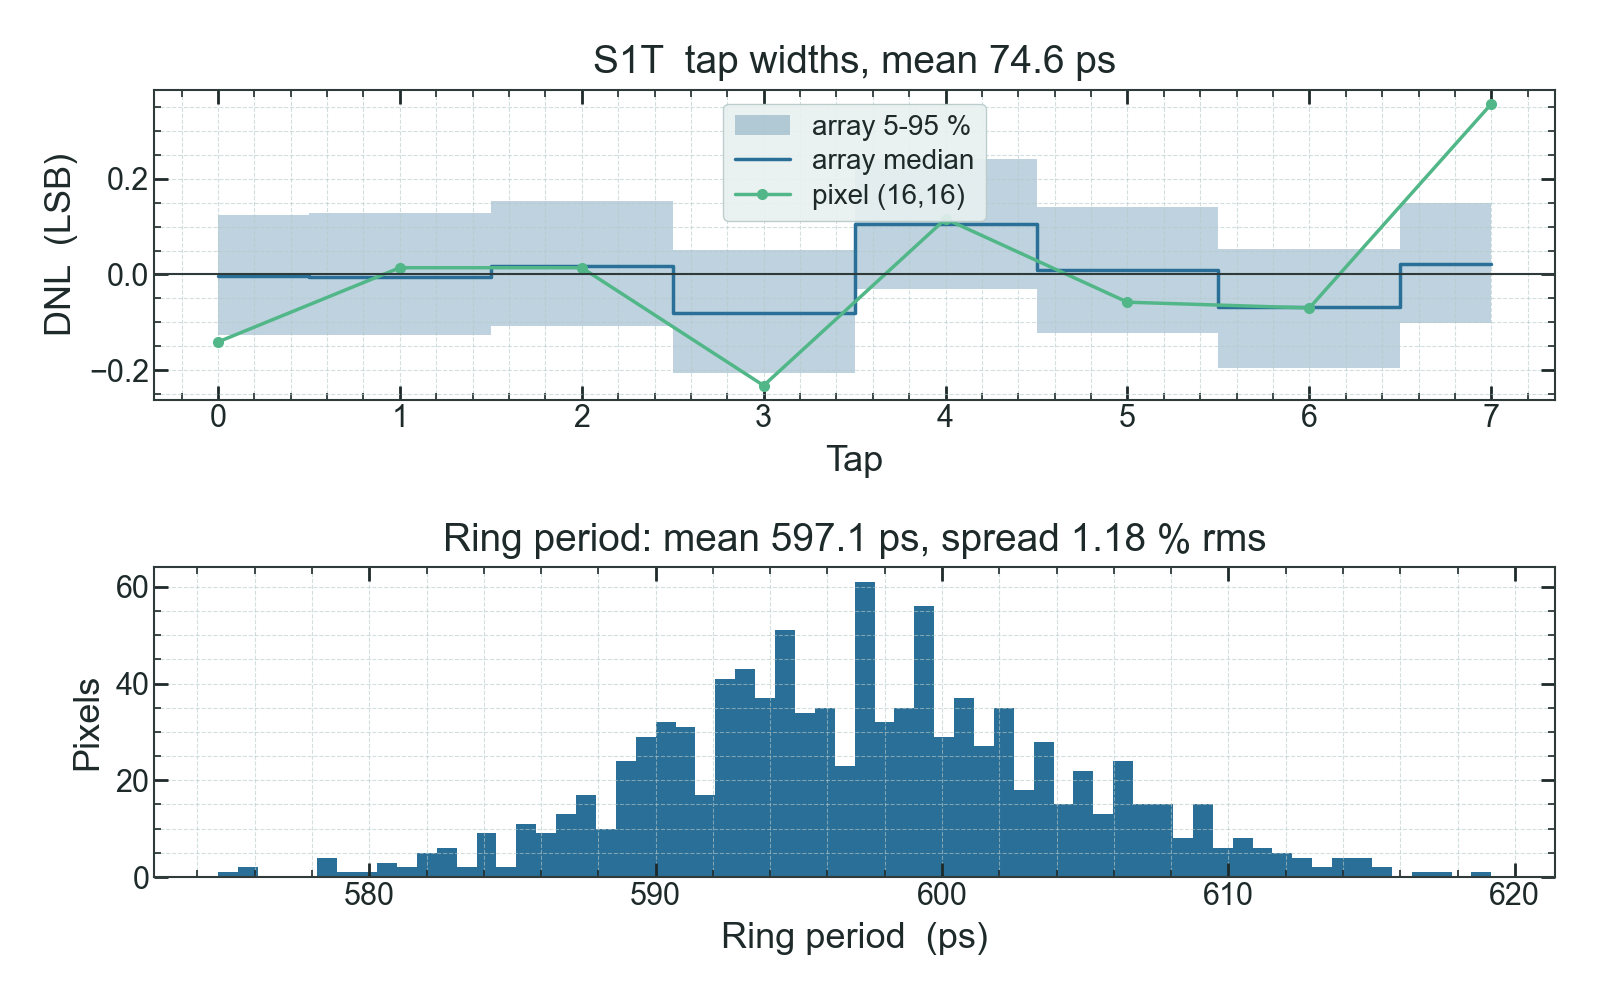

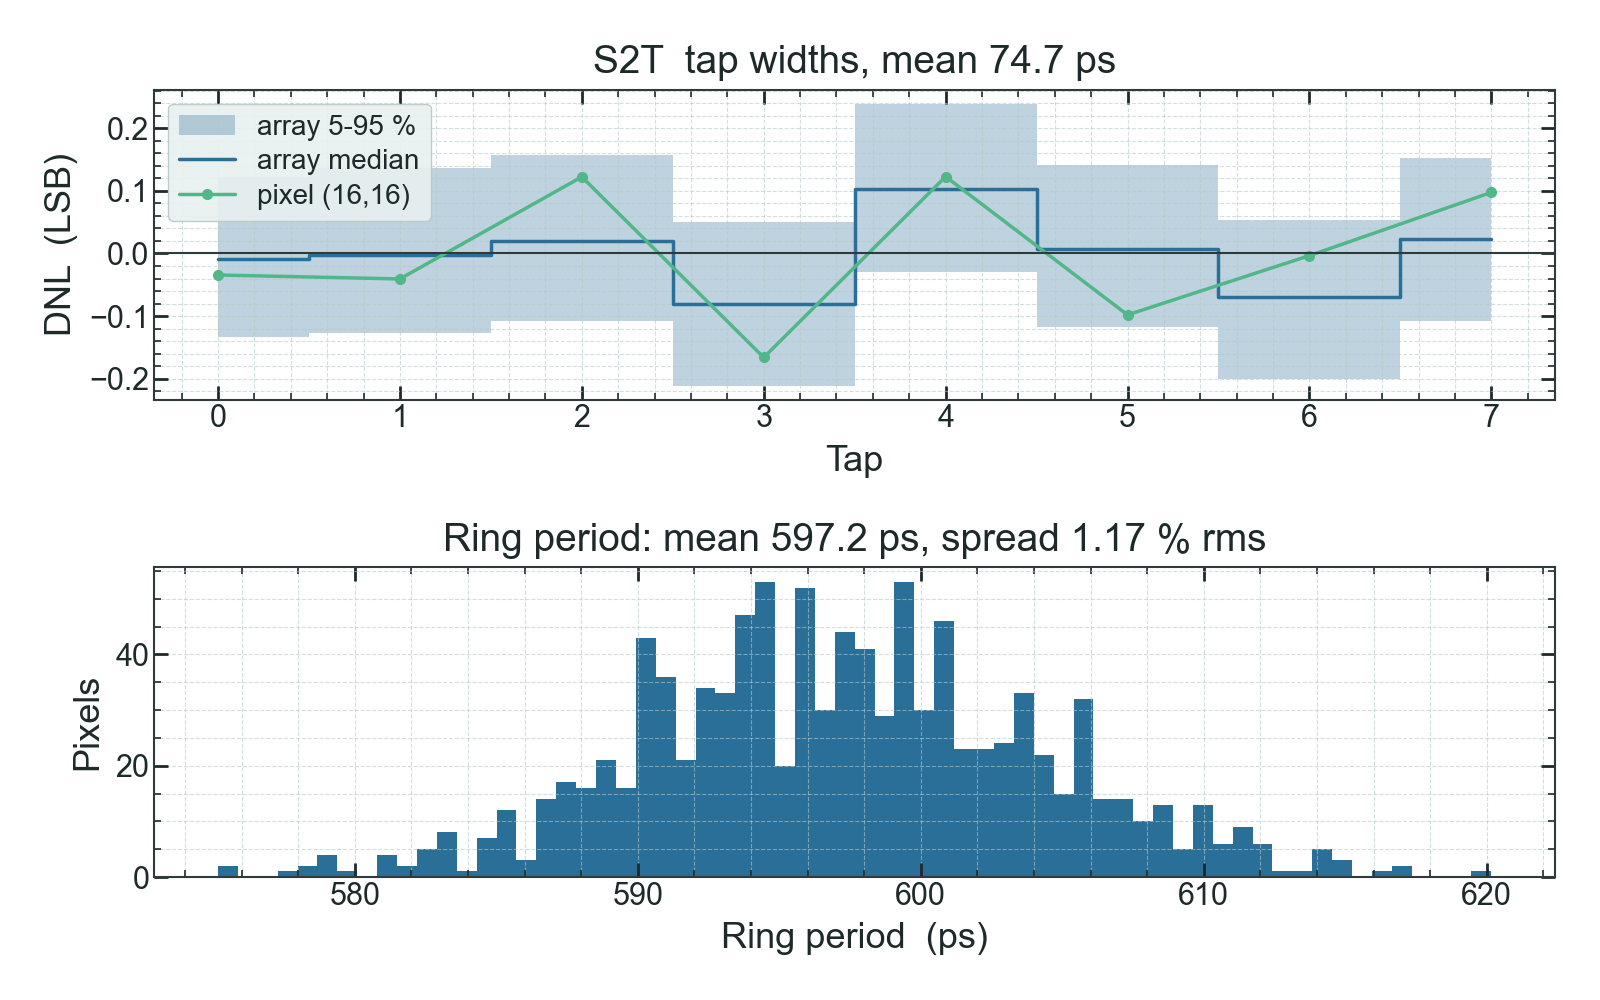

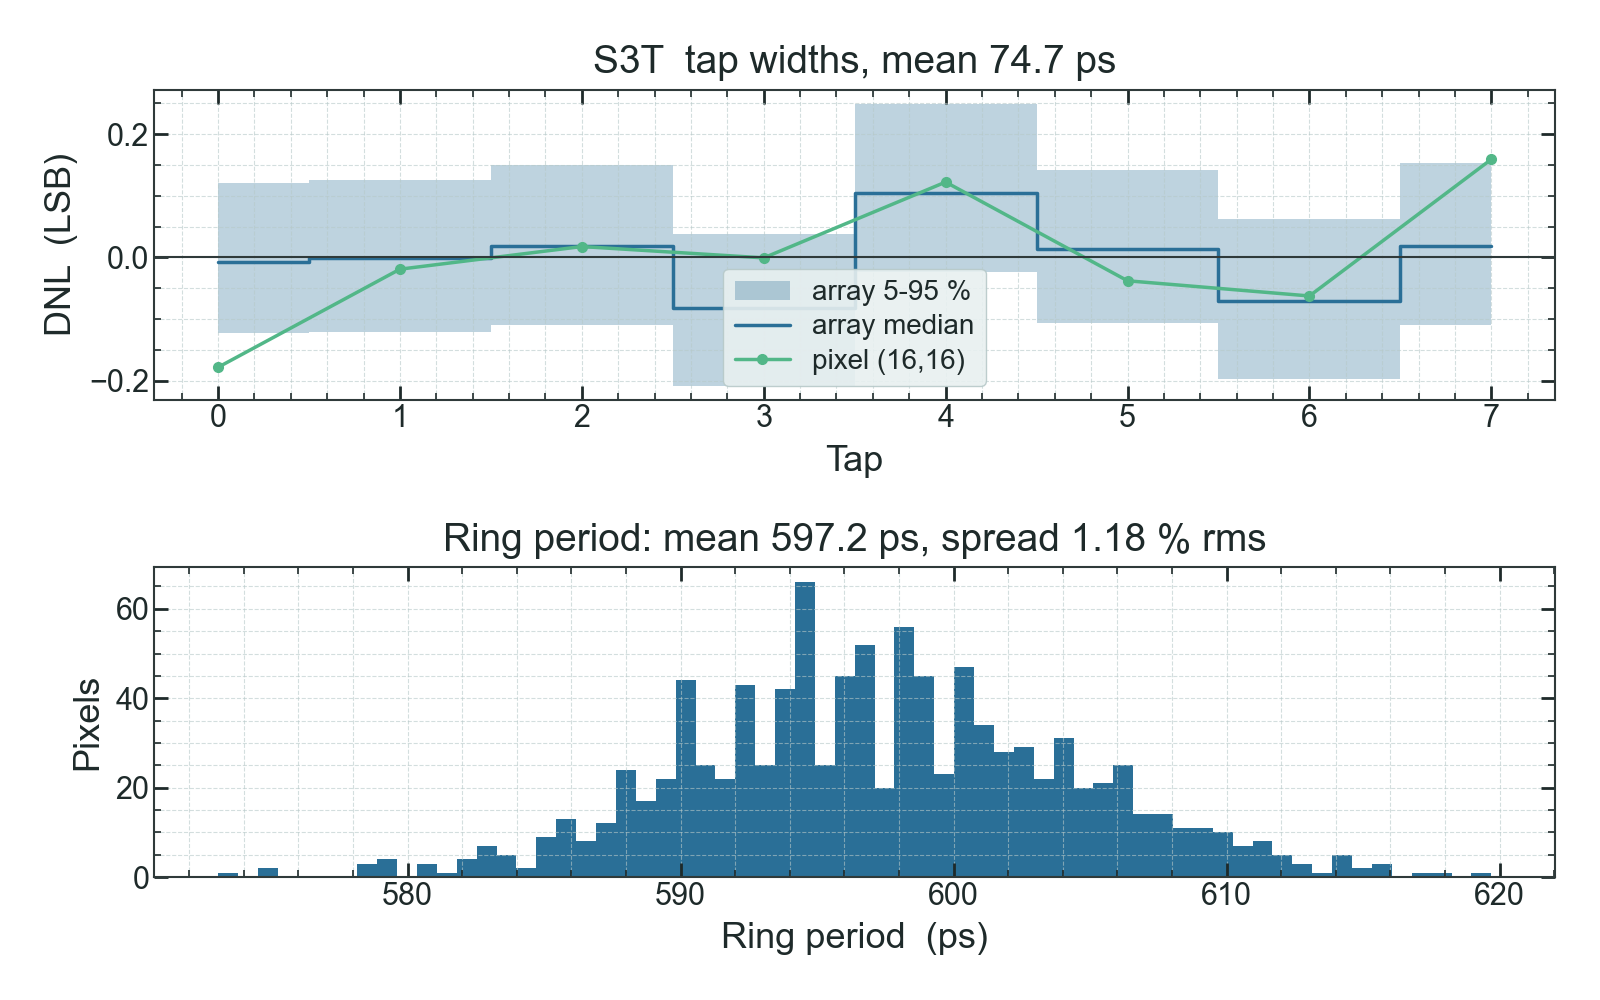

S0: ring 597.1 ps, 1.17 % rms, LSB 74.64 ps


In [5]:
tables = tc.plot_tdc_calibration(path, pixel=(16, 16))
show_figures(path, "tdc_calibration")

taps = tables["S0T"]  # (32, 32, 8), ps
ring = taps.sum(axis=-1)  # ring period per pixel, ps
print(
    f"S0: ring {ring.mean():.1f} ps, {ring.std() / ring.mean() * 100:.2f} % rms, "
    f"LSB {taps.mean():.2f} ps"
)

What to look for:

- **One pixel far outside the band:** inspect it with
  `tc.plot_tdc_calibration(path, pixel=(r, c))`.
- **The four SPADs disagreeing on the ring period by more than ~0.1 %:**
  suspicious, since they share the design.
- **Dead pixels:** reported by `process_tdc_calibration`. They fall back to a
  flat nominal lap.

## 4. Convert codes with the table

`core.calibration.codes_to_ps` applies the table to any code at any clock:

In [6]:
import numpy as np

from dapkel.core import calibration

codes = np.arange(0, 40)
t_ps = calibration.codes_to_ps(codes, taps[16, 16])
print(np.diff(t_ps)[:8])  # the 8 tap widths of pixel (16, 16)

[66.45064337 80.30431107 82.17299083 81.01851852 75.82199546 67.08238851
 72.51511716 68.55552872]


## 5. Ship it so the coincidence analysis uses it

The coincidence pipeline reads packaged tables by board number. Copy the four
tables into `src/dapkel/params/calibration_data/` under the names
`<daughterboard>_<motherboard>_TDC_COMPACT_<tag>.npy`, for example
`D0_M0_TDC_COMPACT_S0T.npy` (the older `..._SPAD0_S0.npy` names are read too).
Then
`process_coincidences(..., daughterboard_number="D0", motherboard_number="M0")`
picks them up:

- an `S<n>T` run gets that SPAD's table;
- an `ORT` run gets the mean of the four.

Copying over existing files replaces the board's current calibration, so keep
the old ones somewhere first.

## Next

[Coincidences](06_coincidences.ipynb) applies the calibration with
`apply_TDC_calibration=True`.